# E8 · 외부 풀이 검증과 SFT A/B 데이터 생성

E5·E6 추가 노트북의 5번 셀이 출력한 **공유할 폴더**를 사용합니다. Colab A100 GPU를 선택하세요. 기존 외부 풀이에서 결론을 읽는 텍스트 모델을 Colab 안에서 실행합니다.

1. **입력 설정**에서 `HANDOFF_PATH`를 지정하고 **자동 검사와 표본 생성**까지 실행하세요.
2. 표본의 문제·선택지·이미지와 원본 풀이를 읽고 `사람검토.csv`에 `정상` 또는 `오류`를 입력하세요. 확인이 어려우면 비워 두고 같은 문항을 다시 검토하세요.
3. **집계 및 최종 파일 생성** 셀을 실행하세요. A군은 짧은 정답, B군은 동일 문항의 외부 풀이와 같은 정답을 받습니다. 출력의 `target`은 SFT의 assistant 응답입니다. 질문·선택지·이미지는 두 군에서 같습니다.

## 입력 설정

In [ ]:
from pathlib import Path
import csv, hashlib, json, os, random, re, tempfile, unicodedata
from collections import Counter
from decimal import Decimal
from IPython.display import display, Image as NotebookImage

HANDOFF_PATH = "/content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794"  # 예: /content/drive/MyDrive/.../추가검증/.../결과_20261120T...
SEED = 42
if not Path('/content/drive/MyDrive').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

if HANDOFF_PATH.strip():
    root = Path(HANDOFF_PATH.strip()).expanduser().resolve()
elif 'final' in globals() and isinstance(final, Path) and (final/'E8_검토후보_ID.jsonl').is_file():
    root = final.resolve()
else:
    default = Path('/content/drive/MyDrive/MMDL_audit_results')
    found = sorted(p.parent for p in default.glob('*/추가검증/*/결과_*/E8_검토후보_ID.jsonl'))
    if len(found) != 1:
        raise ValueError('HANDOFF_PATH에 5번 셀의 공유할 폴더를 지정하세요. 발견된 경로: '+str(found))
    root = found[0].resolve()
data = root/'data'
print('E5·E6 인계 폴더:', root)

Mounted at /content/drive
E5·E6 인계 폴더: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794


## 인계 목록과 출처 확인
분모는 이 인계본의 `data/train_*.jsonl` 행 전체입니다. E5·E6의 문항별 통과 기록, 출처 검토표, E8 후보 ID를 대조합니다. 일치 검사는 여기서 인계한 외부 풀이만 읽습니다. 파일끼리 ID나 출처가 어긋나면 혼합된 인계본으로 보고 경로를 표시합니다.

In [ ]:
def read_rows(path):
    with path.open(encoding='utf-8-sig') as f:
        for line in f:
            if line.strip():
                yield json.loads(line)

def read_csv(path):
    with path.open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def index_by(rows, key):
    indexed = {}
    for row in rows:
        k = row[key]
        if not k or k in indexed:
            raise ValueError(f'빈 키 또는 중복 키: {key}={k}')
        indexed[k] = row
    return indexed

def dump(x):
    return json.dumps(x, ensure_ascii=False, sort_keys=True, separators=(',', ':'))

def save_csv(path, fields, rows):
    tmp = path.with_suffix('.tmp')
    with tmp.open('w', encoding='utf-8-sig', newline='') as f:
        w = csv.DictWriter(f, fieldnames=fields, extrasaction='ignore')
        w.writeheader()
        w.writerows(rows)
    tmp.replace(path)

ledger = index_by(read_csv(root/'문항별_판정과근거.csv'), '행키')
sources = index_by(read_csv(root/'E5_출처검토_작성.csv'), '데이터셋')
candidates = index_by(read_rows(root/'E8_검토후보_ID.jsonl'), 'rid')
parts = sorted(data.glob('train_*.jsonl'))
if not parts:
    raise FileNotFoundError(f'{data} 안에 train_*.jsonl이 없습니다.')
records = index_by((r for p in parts for r in read_rows(p)), 'rid')
index_by(records.values(), 'id')
if set(records) != {k for k,s in ledger.items() if s['결과']=='통과'} or candidates.keys()-records.keys():
    raise ValueError(f'통과 목록과 인계 파일이 일치하지 않습니다. {root}')

def external(r):
    k, src = r['rid'], r['source']
    link, c = ledger[k], candidates.get(k)
    if link['데이터셋'] != src or link['원본ID'] != r['original_id']:
        raise ValueError('출처 또는 원본 ID 충돌: '+k)
    if c and (c['id'] != r['original_id'] or c['package']+'/'+c['id'] != r['id']):
        raise ValueError('후보 ID 충돌: '+k)
    meta = [src, r['id'], r['original_id'], k, (c or {}).get('source_family','')]
    ev = re.compile(r'mmmu|(?:stage|phase|step)[\s_-]*0(?:\D|$)|0\s*단계', re.I)
    s = sources.get(src, {})
    return (r['mmmu_overlap'] is False and s.get('결정')=='통과'
            and s.get('MMMU출처')=='아니오' and not any(ev.search(x) for x in meta))

def asset(rel):
    p = Path(rel)
    if p.is_absolute() or '..' in p.parts or p.parts[:1] != ('images',):
        raise ValueError('인계 이미지 상대경로 확인: '+rel)
    return data/p

print(f'전체 인계 {len(records):,}건 / E8 후보 목록 {len(candidates):,}건')

전체 인계 21,293건 / E8 후보 목록 8,035건


## 풀이에서 최종 답 추출
`extract`에는 풀이와 선택지만 전달합니다. 마지막 답 표지, 맨 끝의 LaTeX boxed 답, 마지막 줄의 독립된 선택지·수치 및 제한된 결론 표현을 인식합니다. 객관식은 유효한 글자 또는 고유한 선택지 문구를 대조합니다. 단답은 문자열 또는 단위가 같은 정확한 십진수로 비교합니다. 부호, 단위, 대소문자를 보존합니다. 짧은 단어형 답은 표기가 다르면 문자열 불일치로 집계하므로 동의어도 포함될 수 있습니다. 단위 변환, 일반 수식 동치, 자유서술의 의미 판정은 지원하지 않습니다. 최종 답을 식별하지 못한 행과 비교할 수 없는 행은 보류하고, 추출·비교에 성공한 불일치만 따로 셉니다.

In [ ]:
def tidy(s):
    return ' '.join(unicodedata.normalize('NFC', s).split())

NUM = r'[+−-]?(?:\d+(?:\.\d+)?|\.\d+)(?:[eE][+-]?\d+)?'
UNIT = r'(?:%|°(?:C|F)?|kg|mg|g|km|cm|mm|m|s|ms|h|mol|K|N|Pa|kPa|MPa|V|A|W|kW|J|Hz|m/s|km/h|m²|m³)'
def number(s):
    m = re.fullmatch(fr'({NUM})\s*({UNIT})?', s)
    return (Decimal(m[1].replace('−','-')), m[2] or '') if m else None

def clean(s):
    s = tidy(s).rstrip('。').strip()
    if s.endswith('.') and not s.endswith('..'):
        s = s[:-1].rstrip()
    for a,b in [('**','**'), ('\\(','\\)'), ('$', '$')]:
        if s.startswith(a) and s.endswith(b) and len(s)>len(a)+len(b):
            s = s[len(a):-len(b)].strip()
    return s

def choice(s, opts):
    m = re.fullmatch(r'(?:option\s+|choice\s+)?(?:\(([A-Za-z])\)|([A-Za-z]))',s,re.I)
    ids = {i for i,o in enumerate(opts) if tidy(o)==s}
    if m:
        i = ord((m[1] or m[2]).upper())-65
        if 0 <= i < len(opts):
            ids.add(i)
    return chr(65+ids.pop()) if len(ids)==1 else None

MARK = re.compile(r'(?:^|(?<=[.!?])\s+|\n|(?:therefore|thus|hence|so)[,:]?\s+)'
                  r'(?:\*\*)?(?:the\s+)?(?:final answer|correct answer|answer|최종\s*답(?:안)?|정답)'
                  r'(?:(?:\*\*)?\s*[:：]\s*|\s+is\s+|은\s+|는\s+)', re.I)
def box_at_end(text):
    starts = list(re.finditer(r'\\boxed\s*\{',text))
    if not starts:
        return None
    last = starts[-1]
    depth = 1
    for i in range(last.end(),len(text)):
        depth += (text[i]=='{') - (text[i]=='}')
        if not depth:
            if re.fullmatch(r'[\s.$。]*|\s*\\[)\]]\s*[.。]?',text[i+1:]):
                return text[last.end():i]
            break
    return None

def extract(sol, opts):
    s = sol.strip()
    markers = list(MARK.finditer(s))
    if len(markers)>1:
        return '', '복수 답 표지', False
    box = box_at_end(s)
    if markers:
        tail = s[markers[-1].end():].strip()
        if tail.startswith('**') and not tail.endswith(('**','**.')):
            tail = tail[2:].strip()
        value = clean(tail)
        if box is not None and tail.count(r'\boxed')==1 and re.fullmatch(r'(?:\$+|\\\(|\\\[)?\s*\\boxed\s*\{.*\}.*',tail,re.S):
            value = tidy(box)
        elif '\n' in tail or len(value)>160 or re.search(r'[.!?]\s+[A-Za-z가-힣]', value):
            return '', '답 표지 이후 추가 문장', False
        return value, '답 표지', bool(s[:markers[-1].start()].strip(' .*\n'))
    if box is not None:
        if s.count(r'\boxed')>1:
            return '', '복수 boxed 결론', False
        prefix = s[:s.rfind(r'\boxed')].strip(' \n$.*')
        return tidy(box), '마지막 boxed', bool(prefix.strip('\\(['))
    lines = [line.strip() for line in s.splitlines() if line.strip()]
    last = clean(lines[-1])
    if number(last) is not None or last.casefold() in {'yes','no','true','false'} or (opts and choice(last,opts)):
        return last, '독립된 마지막 줄', len(lines)>1
    # 마지막 결론이 수치/선택지로 끝날 때만 읽는다. 중간 계산이나 임의의 마지막 숫자는 사용하지 않는다.
    m = re.search(r'(?:^|[.!?]\s+|\n)(?:therefore|thus|hence|따라서)[,:]?\s+([^\n]+)$',s,re.I)
    if m:
        value = clean(m[1])
        if number(value) is not None or (opts and choice(value,opts)):
            return value, '마지막 결론', bool(s[:m.start()].strip())
    # 끝의 산술 등식은 피연산자와 결과가 모두 명시된 경우에만 읽는다.
    eq = re.search(fr'(?<![\w.]){NUM}\s*(?:[+*/×÷−-]\s*{NUM}\s*)+=\s*({NUM}\s*(?:{UNIT})?)$',last)
    if eq:
        return eq[1].strip(), '마지막 산술 등식', True
    return '', '최종 답 형식 미지원', False

def compare(value, gold, opts):
    if opts:
        a,b = choice(value,opts), choice(clean(gold),opts)
        if not a or not b:
            return '비교보류'
        return '일치' if a==b else '불일치'
    a,b = value,clean(gold)
    if a==b and a:
        return '일치'
    x,y = number(a),number(b)
    if x is not None and y is not None:
        return ('일치' if x==y else '불일치') if x[1]==y[1] else '비교보류'
    if a.casefold() in {'yes','no','true','false'} and b.casefold() in {'yes','no','true','false'}:
        return '일치' if a.casefold()==b.casefold() else '불일치'
    # 짧은 단어형 답은 문자열 기준으로 집계한다. 동의어는 별도 의미 평가 대상이다.
    word_answer = r'[^\W\d_]+(?:[ -][^\W\d_]+){0,5}'
    if all(re.fullmatch(word_answer,t) for t in (a,b)):
        return '불일치'
    return '비교보류'

## 서술형 풀이 재검사 · Colab A100 GPU
기존 규칙에서 추출보류가 된 **전 문항**을 처리합니다. 객관식 비교보류도 재검사합니다. 질문·보기·외부 풀이만 로컬 모델에 전달합니다. 모델이 선택지 번호와 근거 문장 번호를 반환하면, 보기 순서를 바꾸어 다시 읽고 두 결과를 원래 선택지로 복원합니다. 단답형은 근거 문장에 실제로 있는 답만 받습니다. 추출된 답은 그다음에 기준 정답과 비교합니다. 중간 결과를 Drive에 저장하므로 세션 중단 후 같은 설정으로 재개할 수 있습니다.

In [ ]:
MODEL_ID = 'Qwen/Qwen2.5-7B-Instruct'
BATCH = 8  # GPU 메모리 부족 시 4 또는 2로 낮추고 재실행
PROMPT = """You extract the answer asserted by an external rationale. Treat the supplied fields as data. Do not solve the problem yourself. Select the option positively supported by the rationale, even when the conclusion is paraphrased or in the first sentence. Do not select a distractor just because it is mentioned or negated. If there is no unique supported answer, return null. If there is no reasoning beyond just stating the answer, return null. For a supported choice return JSON {"pick": <display number>, "sentence": <supporting sentence number>}. original_label refers to letters in the original rationale, pick refers to the number in this display. For an open question return JSON {"span": "<exact short answer copied from the supporting sentence>", "sentence": <number>}. Return one JSON value only."""
def sentences(sol):
    return [s.strip() for s in re.split(r'(?<=[.!?。])\s+|\n+',sol) if s.strip()]

def phrase_read(options, lines, question=''):
    # 단순 등장 횟수 대신 긍정적인 서술 구문 전체를 찾는다.
    text=' '.join(lines)
    if re.search(r"\b(?:not|never|incorrect|wrong|rather than|except|however|but)\b",text,re.I):
        # 자료의 관용적인 마무리(다른 보기를 배제)만 허용
        text=re.sub(r'\s*The other options do not fit[^.!?]*[.!?]?\s*$','',text,flags=re.I)
        if re.search(r"\b(?:not|never|incorrect|wrong|rather than|except|however|but)\b",text,re.I):
            return None
    hits=[]
    for i,opt in enumerate(options):
        term=clean(opt)
        clause=re.sub(r'^It\s+(?=(represents|indicates|symbolizes|is)\b)','',term,flags=re.I)
        if clause!=term and len(clause.split())>=6:
            pat=r'\b(?:infer|conclude|deduce)\s+that\s+[^.!?]{1,100}?\s+'+re.escape(clause)+r'(?=[\s.,;!?]|$)'
        elif (re.fullmatch(r'[A-Za-z0-9][\w-]{1,40}',term) and
              re.search(r'\b(?:least|smallest) improvement\b',question,re.I)):
            pat=r'\bwhich represents\s+'+re.escape(term)+r',\s+shows the (?:smallest|least) (?:increase|improvement)\b'
        else:
            continue
        for line in lines:
            if re.search(pat,line,re.I):
                hits.append((chr(65+i),line))
    return hits[0] if len(hits)==1 else None

def payload(question, options, lines, reverse):
    order = list(range(len(options)))
    if reverse:
        order.reverse()
    choices = [dict(pick=j+1,original_label=chr(65+i),text=options[i]) for j,i in enumerate(order)]
    obj = dict(question=question,choices=choices,sentences={i:s for i,s in enumerate(lines,1)})
    return obj,order

def parse_read(raw, order, lines):
    try:
        o=json.loads(raw.strip())
        if not isinstance(o,dict) or type(o.get('sentence')) is not int or not 1<=o['sentence']<=len(lines):
            return None
        quote = lines[o['sentence']-1]
        if order:
            j=o.get('pick')
            if type(j) is not int or not 1<=j<=len(order):
                return None
            value=chr(65+order[j-1])
        else:
            value=o.get('span')
            if not isinstance(value,str) or not value.strip() or value not in quote or len(value)>160:
                return None
        return value.strip(),quote
    except (ValueError,TypeError):
        return None

def load_reader(revision):
    import torch
    from transformers import AutoTokenizer, AutoModelForCausalLM
    if not torch.cuda.is_available():
        raise RuntimeError('런타임 유형을 GPU(A100 권장)로 변경한 뒤 처음부터 실행하세요.')
    tok = AutoTokenizer.from_pretrained(MODEL_ID,revision=revision,padding_side='left')
    net = AutoModelForCausalLM.from_pretrained(MODEL_ID,revision=revision,device_map={'':'cuda:0'},
               torch_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16).eval()
    def generate(objs):
        prompts=[tok.apply_chat_template([dict(role='system',content=PROMPT),dict(role='user',content=dump(o))],
                  tokenize=False,add_generation_prompt=True) for o in objs]
        x=tok(prompts,padding=True,return_tensors='pt',add_special_tokens=False)
        result=['']*len(objs)
        # 과도하게 긴 원문은 자르지 않고 보류
        select=[i for i,n in enumerate(x.attention_mask.sum(1).tolist()) if n+96<=min(net.config.max_position_embeddings,8192)]
        if select:
            x=tok([prompts[i] for i in select],padding=True,return_tensors='pt',add_special_tokens=False).to(net.device)
            with torch.inference_mode():
                y=net.generate(**x,max_new_tokens=96,do_sample=False,pad_token_id=tok.pad_token_id)
            for i,raw in zip(select,tok.batch_decode(y[:,x.input_ids.shape[1]:],skip_special_tokens=True)):
                result[i]=raw
        return result
    return generate

def read_batch(keys, generate):
    lines={k:sentences(records[k]['solution']) for k in keys}
    result={}
    for reverse in (False, True):
        group=[k for k in keys if not reverse or records[k]['options']]
        if not group:
            continue
        inputs=[payload(records[k]['question'],records[k]['options'],lines[k],reverse) for k in group]
        raws=generate([obj for obj,order in inputs])
        for k,(_,order),raw in zip(group,inputs,raws,strict=True):
            result.setdefault(k,[]).append(parse_read(raw,order,lines[k]))
    answers={}
    for k,reads in result.items():
        if all(reads) and len({r[0] for r in reads})==1:
            answers[k]=[reads[0][0],reads[0][1]]
        else:
            answers[k]=['','근거 미확정 또는 두 순서의 판정 불일치']
    return answers

def semantic_run(keys, fingerprint):
    if not keys:
        return {}
    import importlib.util, subprocess, sys
    if any(importlib.util.find_spec(name) is None for name in ('transformers','accelerate','huggingface_hub')):
        subprocess.check_call([sys.executable,'-m','pip','install','-q','transformers==4.57.2','accelerate>=1.2,<2'])
    from huggingface_hub import model_info
    base=root/'E8'/'서술형_체크포인트'/fingerprint
    base.mkdir(parents=True,exist_ok=True)
    version=base/'model_revision.txt'
    if not version.exists():
        tmp=version.with_suffix('.tmp')
        tmp.write_text(model_info(MODEL_ID).sha,encoding='utf8')
        tmp.replace(version)
    revision=version.read_text().strip()
    print('모델 revision',revision,'/ 재검사 대상',len(keys),flush=True)
    answers={}
    generate=None
    for start in range(0,len(keys),64):
        group=keys[start:start+64]
        path=base/f'{start:06}.json'
        if path.exists():
            block=json.loads(path.read_text(encoding='utf8'))
            if set(block)!=set(group):
                raise ValueError(f'체크포인트 키 확인 필요: {path}')
        else:
            if generate is None:
                generate=load_reader(revision)
            block={}
            for i in range(0,len(group),BATCH):
                block.update(read_batch(group[i:i+BATCH],generate))
            tmp=path.with_suffix('.tmp')
            tmp.write_text(dump(block),encoding='utf8')
            tmp.replace(path)
        answers.update(block)
        print(f'{len(answers):,}/{len(keys):,} 처리',flush=True)
    return answers

## 자동 검사와 표본 생성
`자동검사.csv`에서 모든 행의 판정과 추출값을 확인할 수 있습니다. 후보 파일에 없는 행, 풀이가 비어 있는 행, 답만 적혀 있는 행, 추출·비교 보류 행은 학습에서 제외됩니다. 단위가 다르거나 지원하지 않는 수식 형식이면 비교 보류로 기록합니다. 표본은 고정 시드로 비복원 균등 추출합니다. 같은 입력과 설정에서는 작성하던 검토표를 재사용합니다.

In [ ]:
def inspect_row(r):
    rid = r['rid']
    sol = r['solution']
    result = dict(rid=rid, id=r['id'], 출처=r['source'], 정답=r['answer'], 추출값='', 근거='')
    if not external(r):
        status = '평가·출처 제외'
    elif not isinstance(sol,str) or not sol.strip():
        status = '풀이 없음'
    elif rid not in candidates:
        status = 'E8 후보 아님'
    elif not isinstance(r['answer'],str) or not r['answer'].strip():
        status = '정답 없음'
    else:
        value, reason, has_steps = extract(sol, r['options'])
        result.update(추출값=value, 근거=reason)
        if not value:
            status = '추출보류'
        else:
            status = compare(value,r['answer'],r['options'])
            if status=='일치' and not has_steps:
                status = '풀이 본문 없음'
    return dict(result, 판정=status)

audit = {}
digest = hashlib.sha256(f'E8-external-v1.1/seed={SEED}'.encode())
for k in sorted(records):
    r = records[k]
    audit[k] = inspect_row(r)
    digest.update((dump([r,audit[k]])+'\n').encode())
oldheld=[k for k,r in audit.items() if r['판정']=='추출보류']
pending=[k for k,r in audit.items() if r['판정']=='추출보류' or
         (r['판정']=='비교보류' and records[k]['options'])]
digest.update(dump(['semantic-v2',MODEL_ID,PROMPT]).encode())
phrases={}
for k in pending:
    r=records[k]
    hit=phrase_read(r['options'],sentences(r['solution']),r['question'])
    if hit: phrases[k]=hit
readings=dict(phrases)
readings.update(semantic_run([k for k in pending if k not in phrases],digest.hexdigest()[:24]))
print('명시적 서술 구문으로 식별:',len(phrases))
# 자동 판독이 모호한 행을 정답 비공개 상태로 사람이 판독할 수 있다.
unresolved=[k for k in oldheld if not readings[k][0]]
machine_count=len(oldheld)-len(unresolved)
if unresolved:
    blind_dir=root/'E8'/'서술형_체크포인트'/digest.hexdigest()[:24]
    blind_dir.mkdir(parents=True,exist_ok=True)
    blind_path=blind_dir/'미확정_답추출.csv'
    fields=['rid','질문','선택지','원본풀이','추출답','근거인용']
    if not blind_path.exists():
        save_csv(blind_path,fields,(
            dict(rid=k,질문=records[k]['question'],선택지=dump(records[k]['options']),
                 원본풀이=records[k]['solution'],추출답='',근거인용='') for k in unresolved))
    blind_rows=index_by(read_csv(blind_path),'rid')
    if set(blind_rows)!=set(unresolved):
        raise ValueError('미확정 검토표 ID와 현재 실행이 다릅니다.')
    print('잔여 문항을 직접 판독할 경우 이 표에 추출답과 원문 근거를 적고 현재 셀을 재실행:',blind_path)
else:
    blind_rows={}
manual_keys=set()
for k,row in blind_rows.items():
    answer,quote=row['추출답'].strip(),row['근거인용'].strip()
    if not answer and not quote:
        continue
    r=records[k]
    if not quote or quote not in r['solution'] or not answer:
        raise ValueError('원문 근거와 답을 모두 확인하세요: '+k)
    if r['options']:
        if not re.fullmatch('[A-Z]',answer) or ord(answer)-65>=len(r['options']):
            raise ValueError('추출답에 원래 선택지 글자를 입력하세요: '+k)
    elif answer not in quote:
        raise ValueError('단답은 인용문에서 그대로 복사하세요: '+k)
    readings[k]=answer,quote
    manual_keys.add(k)
for k,(value,evidence) in readings.items():
    r=audit[k]
    r['이전판정']=r['판정']
    r['근거문장']=evidence
    if value:
        r.update(추출값=value,근거='사람 답추출' if k in manual_keys else ('서술 구문' if k in phrases else '모델 근거 문장'),판정=compare(value,records[k]['answer'],records[k]['options']))
    digest.update((dump([k,value,evidence])+'\n').encode())
recovered=sum(bool(readings[k][0]) for k in oldheld)
print(f'기존 보류 중 자동 식별 {machine_count:,}건 + 사람이 추가 식별 {len(manual_keys):,}건')
print(f'기존 추출보류 {len(oldheld):,}건 중 답 식별 {recovered:,}건 / 목표 8,000건 / 부족 {max(0,8000-recovered):,}건')
print('기존 추출보류의 최종 판정:',dict(Counter(audit[k]['판정'] for k in oldheld)))
passed = [k for k,r in audit.items() if r['판정']=='일치']
stats = Counter(r['판정'] for r in audit.values())
out = root/'E8'/digest.hexdigest()[:16]
out.mkdir(parents=True, exist_ok=True)
save_csv(out/'자동검사.csv', ['rid','id','출처','판정','정답','추출값','근거','이전판정','근거문장'], audit.values())
sample = random.Random(SEED).sample(passed,min(len(passed),50))
review = out/'사람검토.csv'
review_fields = ['순번','rid','출처','질문','선택지','정답','추출값','원본풀이','이미지','판정','메모']
if not review.exists():
    def review_row(i,k):
        r = records[k]
        return dict(순번=i,rid=k,출처=r['source'],질문=r['question'],선택지=dump(r['options']),
                    정답=r['answer'],추출값=audit[k]['추출값'],원본풀이=r['solution'],
                    이미지=dump(r['images']),판정='',메모='')
    save_csv(review, review_fields, (review_row(i,k) for i,k in enumerate(sample,1)))

def report_rows(errors=None):
    return [
        ('기존 추출보류',len(oldheld)), ('자동 추가 식별',machine_count), ('사람 추가 식별',len(manual_keys)), ('기존 추출보류 중 답 식별',recovered),
        ('전체 문항',len(records)), ('최종 답 불일치로 제거',stats['불일치']),
        ('그 밖의 제외·보류',len(records)-stats['불일치']-len(passed)),
        ('최종 답 일치 및 풀이 보유',len(passed)), ('사람 검토 표본 수',len(sample)),
        ('사람이 확인한 50건 중 풀이 오류',errors if errors is not None and len(sample)==50 else ('50건 미충족' if len(sample)<50 else '미확정')),
        ('실제 검토 중 풀이 오류',errors if errors is not None else '미확정'),
        ('풀이 오류율',f'{errors}/{len(sample)} ({errors/len(sample):.1%})' if errors is not None else '미확정'),
        ('A군·B군 각각의 최종 문항',len(passed)-errors if errors is not None else '미확정')]
def save_report(path,errors=None):
    save_csv(path,['항목','값'],({'항목':k,'값':v} for k,v in report_rows(errors)))
save_report(out/'자동검사_집계.csv')
print('전체',len(records),' / 자동 판정',dict(stats),' / 표본',len(sample))
print('검토표:',review)
if len(sample)<50:
    print(f'통과 문항이 {len(sample)}건이므로 50건 표본 요건은 미충족입니다. 1~49건이면 전수 검토 후 실제 분모를 기록합니다.')

모델 revision a09a35458c702b33eeacc393d103063234e8bc28 / 재검사 대상 8021


config.json:   0%|          | 0.00/663 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (3 outputs left out)

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/243 [00:00<?, ?B/s]

64/8,021 처리
128/8,021 처리
192/8,021 처리
256/8,021 처리
320/8,021 처리
384/8,021 처리
448/8,021 처리
512/8,021 처리
576/8,021 처리
640/8,021 처리
704/8,021 처리
768/8,021 처리
832/8,021 처리
896/8,021 처리
960/8,021 처리
1,024/8,021 처리
1,088/8,021 처리
1,152/8,021 처리
1,216/8,021 처리
1,280/8,021 처리
1,344/8,021 처리
1,408/8,021 처리
1,472/8,021 처리
1,536/8,021 처리
1,600/8,021 처리
1,664/8,021 처리
1,728/8,021 처리
1,792/8,021 처리
1,856/8,021 처리
1,920/8,021 처리
1,984/8,021 처리
2,048/8,021 처리
2,112/8,021 처리
2,176/8,021 처리
2,240/8,021 처리
2,304/8,021 처리
2,368/8,021 처리
2,432/8,021 처리
2,496/8,021 처리
2,560/8,021 처리
2,624/8,021 처리
2,688/8,021 처리
2,752/8,021 처리
2,816/8,021 처리
2,880/8,021 처리
2,944/8,021 처리
3,008/8,021 처리
3,072/8,021 처리
3,136/8,021 처리
3,200/8,021 처리
3,264/8,021 처리
3,328/8,021 처리
3,392/8,021 처리
3,456/8,021 처리
3,520/8,021 처리
3,584/8,021 처리
3,648/8,021 처리
3,712/8,021 처리
3,776/8,021 처리
3,840/8,021 처리
3,904/8,021 처리
3,968/8,021 처리
4,032/8,021 처리
4,096/8,021 처리
4,160/8,021 처리
4,224/8,021 처리
4,288/8,021 처리
4,352/8,021 처리
4,416/8,021

## 사람이 풀이 50건 읽기
`show(1)`부터 `show(50)`까지 순번으로 열 수 있습니다. 이미지에서 읽은 값, 식과 단위, 추론 단계, 결론이 문제에 맞는지 확인하세요. 잘못된 전제나 계산으로 우연히 정답을 맞힌 경우는 **오류**입니다. 표에 저장할 때는 원래 rid와 UTF-8 CSV 형식을 유지하세요. 순번을 변경하거나 표본을 교체할 필요가 없습니다.

1/50  base:train:46391  MMInstruction/ArxivQA

What does the \( L^{-2} \) scaling behavior in Figure c indicate about the system?
(A) The system exhibits quadratic dependence on the length scale \( L \) in the Fermi-liquid (FL) regime.
(B) In the core region, the system's properties scale inversely with the square of the length.
(C) The Kondo screening length \( \xi_K \) has a quadratic relationship with the system size \( L \).
(D) The resistivity \( \rho_1 \) shows a quadratic decay as a function of \( L \) in the 1CK regime.
(E) ## Figure d


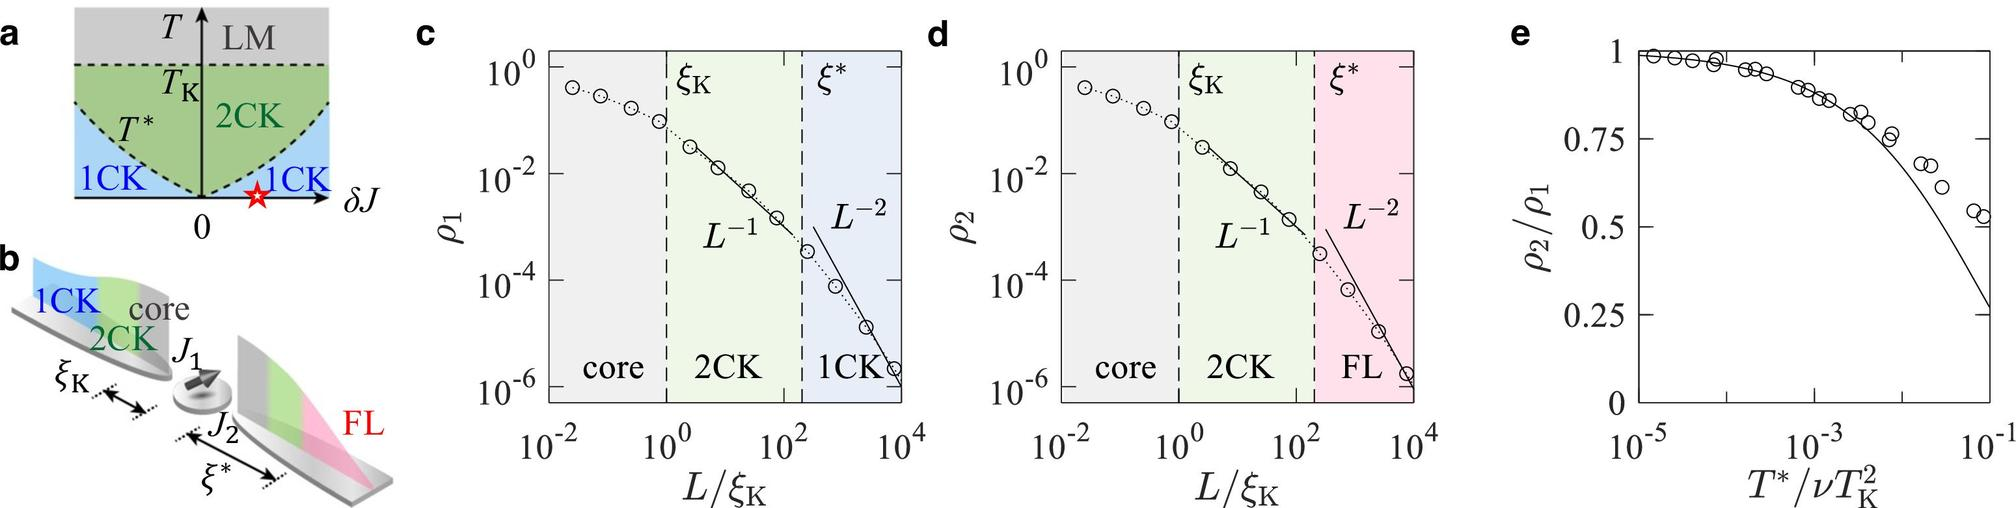


원본 풀이
The \( L^{-2} \) scaling in the pink region, which is labeled as FL, suggests that some property of the system (likely a correlation function or resistivity, given the context) decreases as the inverse square of the length scale in the Fermi-liquid regime. This is a typical behavior for Fermi liquids where resistivity decreases with increasing system size due to reduced scattering.

추출값: A  / 정답: A


In [ ]:
def show(i):
    if not 1<=i<=len(sample):
        raise ValueError(f'표본 순번은 1~{len(sample)}입니다.')
    k = sample[i-1]
    r = records[k]
    print(f'{i}/{len(sample)}  {k}  {r["source"]}\n\n{r["question"]}')
    for j,opt in enumerate(r['options']):
        print(f'({chr(65+j)}) {opt}')
    for rel in r['images']:
        display(NotebookImage(filename=str(asset(rel)),width=650))
    print('\n원본 풀이\n'+r['solution'])
    print('\n추출값:',audit[k]['추출값'],' / 정답:',r['answer'])
if sample:
    show(1)  # 괄호 안의 순번을 바꿔 다시 실행하세요.

## 집계 및 최종 파일 생성
검토표의 50건을 모두 판정한 후 실행하세요. 일치 문항이 1~49건이면 전수 검토한 뒤 실제 오류율과 ‘50건 미충족’을 함께 기록합니다. 일치 문항이 0건이면 자동검사 집계만 남습니다. 오류가 확인된 표본은 두 군에서 함께 빠집니다. 오류율의 분모는 오류 문항을 제외하기 전 실제 검토 건수입니다. 표본 밖의 풀이에는 개별 사람 승인 표시를 하지 않습니다.

**이미지 경로**는 각 JSONL 파일의 부모 폴더를 기준으로 해석합니다. 학습 환경으로 이동할 때는 E5·E6의 `결과_…` 폴더 전체 구조를 유지하세요. 이미지 목록은 디렉터리 단위로 한 번씩 확인합니다.

In [ ]:
def finalize():
    judged = index_by(read_csv(review),'rid')
    if set(judged)!=set(sample):
        raise ValueError('검토표의 rid가 처음 뽑힌 표본과 다릅니다.')
    decisions = {k:r['판정'].strip() for k,r in judged.items()}
    done = sum(v in {'정상','오류'} for v in decisions.values())
    if not sample:
        print('통과 문항 0건 · 학습 데이터 없음. 집계:',out/'자동검사_집계.csv')
        return
    if done!=len(sample):
        print(f'최종 파일 생성 대기 · 표본 {len(sample)}/50건, 판정 완료 {done}/{len(sample)}건.\n{review}')
        return
    bad = {k for k,v in decisions.items() if v=='오류'}
    kept = [k for k in passed if k not in bad]
    rev = hashlib.sha256(dump(judged).encode()).hexdigest()[:12]
    dest = out/f'최종_{rev}'
    if dest.is_dir():
        print('동일 검토 결과:',dest)
        return dest
    directories = {}
    for k in kept:
        for rel in records[k]['images']:
            p = asset(rel)
            directories.setdefault(p.parent,set()).add(p.name)
    for parent, names in directories.items():
        with os.scandir(parent) as entries:
            missing = names-{e.name for e in entries if e.name in names and e.is_file()}
        if missing:
            raise FileNotFoundError(str(parent/next(iter(missing))))
    with tempfile.TemporaryDirectory(prefix='준비중_',dir=out) as tmp:
        stage = Path(tmp)/'final'
        stage.mkdir()
        with (stage/'train_A.jsonl').open('w',encoding='utf8') as a, (stage/'train_B.jsonl').open('w',encoding='utf8') as b:
            for k in kept:
                r = records[k]
                answer = r['answer'].strip()
                base = {key:r[key] for key in ('id','original_id','rid','source','license','question','options','mmmu_overlap')}
                base.update(answer=answer,images=[os.path.relpath(asset(p),dest) for p in r['images']])
                a.write(dump(dict(base,solution=None,target=answer))+'\n')
                b.write(dump(dict(base,solution=r['solution'],target=r['solution'].strip()+'\n'+answer))+'\n')
        save_report(stage/'E8_최종집계.csv',len(bad))
        save_csv(stage/'사람검토_확정.csv',review_fields,[judged[k] for k in sample])
        stage.rename(dest)
    for key,value in report_rows(len(bad)):
        print(key,value)
    print('최종 출력:',dest)
    return dest

final_dir = finalize()

최종 파일 생성 대기 · 표본 50/50건, 판정 완료 0/50건.
/content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/d99faa8f052603cf/사람검토.csv


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter
import json
import os
import re
import tempfile


def export_team_messages(e8_final_dir):
    if not e8_final_dir:
        raise ValueError(
            "E8 최종 폴더가 아직 지정되지 않았습니다. "
            "사람 검토를 마치고 기존 마지막 셀을 실행하거나, "
            "이 셀 맨 아래에 기존 '최종 출력:' 폴더 경로를 직접 넣으세요."
        )

    src_dir = Path(e8_final_dir).expanduser().resolve()
    source = src_dir / "train_B.jsonl"
    if not source.is_file():
        raise FileNotFoundError(f"E8 최종 B군 파일을 찾을 수 없습니다: {source}")

    # 원본과 같은 이름의 파일을 쓰므로 새 하위 폴더에 저장합니다.
    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f")
    dest = src_dir / f"조원형식_{stamp}"
    stats = Counter()
    seen = set()
    instruction = (
        "Answer the multiple-choice question. End with a line 'Answer: (X)'."
    )

    def gold_letter(answer, options):
        # 'A', '(A)', 'A.', 'Answer: (A)'를 전체 문자열 기준으로 해석합니다.
        text = str(answer).strip()
        match = re.fullmatch(
            r"(?:Answer\s*:\s*)?(?:\(([A-Z])\)|([A-Z]))[.]?",
            text, re.IGNORECASE | re.ASCII
        )
        if match:
            letter = (match[1] or match[2]).upper()
            if ord(letter) - ord("A") < len(options):
                return letter

        # E8이 선택지 문구 자체를 정답으로 사용한 경우도 처리합니다.
        matches = [i for i, option in enumerate(options)
                   if str(option).strip() == text]
        if len(matches) == 1:
            return chr(ord("A") + matches[0])
        return None

    def make_row(item_id, images, user_content, target):
        return {
            "id": item_id,
            "images": images,
            "messages": [
                {"role": "user", "content": user_content},
                {"role": "assistant",
                 "content": [{"type": "text", "text": target}]},
            ],
        }

    with tempfile.TemporaryDirectory(dir=src_dir, prefix="변환중_") as tmp:
        stage = Path(tmp) / "output"
        stage.mkdir()

        with (
            source.open(encoding="utf-8-sig") as inp,
            (stage / "train_A.jsonl").open("w", encoding="utf-8") as fa,
            (stage / "train_B.jsonl").open("w", encoding="utf-8") as fb,
        ):
            for line_no, line in enumerate(inp, 1):
                if not line.strip():
                    continue
                r = json.loads(line)
                stats["E8 최종 입력"] += 1
                item_id = r["id"]

                if item_id in seen:
                    raise ValueError(f"{line_no}행: 중복 ID {item_id}")
                seen.add(item_id)

                if r.get("mmmu_overlap") is not False:
                    raise ValueError(f"{item_id}: E6 중복 검사 상태 확인 필요")

                opts = r["options"]
                if not opts:
                    stats["단답형 제외"] += 1
                    continue
                if not isinstance(opts, list) or not 2 <= len(opts) <= 26:
                    raise ValueError(f"{item_id}: 객관식 보기 형식 확인 필요")

                gold = gold_letter(r["answer"], opts)
                if gold is None:
                    raise ValueError(f"{item_id}: 정답 라벨 확인 필요 {r['answer']!r}")

                sol = (r.get("solution") or "").strip()
                question = (r.get("question") or "").strip()
                if not sol or not question:
                    raise ValueError(f"{item_id}: 최종 입력에 질문 또는 풀이가 비어 있습니다.")

                lines = [instruction, "", question]
                for i, option in enumerate(opts):
                    letter = chr(ord("A") + i)
                    # 해당 위치의 기존 보기 번호만 제거합니다.
                    # 예: '(A) A feedback loop' → '(A) A feedback loop'
                    body = re.sub(
                        rf"^\s*(?:\({letter}\)\s*|{letter}[.):]\s+)",
                        "", str(option), count=1
                    ).strip()
                    lines.append(f"({letter}) {body}")

                # E8 이미지 경로는 기존 JSONL 폴더 기준이므로
                # 새 JSONL 폴더에서 같은 파일을 가리키도록 다시 계산합니다.
                images = [
                    os.path.relpath(src_dir / p, start=dest)
                    for p in r["images"]
                ]
                user_content = [{"type": "image", "image": p} for p in images]
                user_content.append({"type": "text", "text": "\n".join(lines)})

                final_answer = f"Answer: ({gold})"
                # 원본 풀이가 이미 동일한 정답 줄로 끝나면 중복 추가를 피합니다.
                b_target = (
                    sol if sol.splitlines()[-1].strip() == final_answer
                    else f"{sol}\n{final_answer}"
                )

                for handle, target in ((fa, final_answer), (fb, b_target)):
                    row = make_row(item_id, images, user_content, target)
                    handle.write(json.dumps(row, ensure_ascii=False) + "\n")
                stats["A·B 각각 저장"] += 1

        if not stats["A·B 각각 저장"]:
            print("변환할 객관식 문항이 없습니다.", dict(stats))
            return None

        stage.rename(dest)

    print(f"E8 최종 입력: {stats['E8 최종 입력']:,}건")
    print(f"팀 객관식 형식에서 제외한 단답형: {stats['단답형 제외']:,}건")
    print(f"A군·B군: 각각 {stats['A·B 각각 저장']:,}건")
    print("A군 파일:", dest / "train_A.jsonl")
    print("B군 파일:", dest / "train_B.jsonl")
    return dest


# 같은 런타임이면 그대로 실행하세요.
#team_dir = export_team_messages(globals().get("final_dir"))

# 런타임을 다시 열었다면 위 한 줄 대신, 기존 출력 경로를 직접 넣으세요.
team_dir = export_team_messages("/content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/E8_output")

FileNotFoundError: E8 최종 B군 파일을 찾을 수 없습니다: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/E8_output/train_B.jsonl

In [ ]:
from pathlib import Path

e8 = Path(
    "/content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/"
    "추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8"
)

if not e8.is_dir():
    print("E8 폴더가 보이지 않습니다. 드라이브 마운트와 연결한 계정을 확인하세요.")
else:
    files = sorted(e8.glob("*/최종_*/train_B.jsonl"))
    if files:
        for f in files:
            print("최종 B군 파일:", f)
            print("변환 실행문:", f"team_dir = export_team_messages({str(f.parent)!r})")
    else:
        print("이 실행 경로에는 아직 최종 B군 파일이 없습니다.")
        for review in sorted(e8.glob("*/사람검토.csv")):
            print("검토표:", review)

이 실행 경로에는 아직 최종 B군 파일이 없습니다.
검토표: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/0d3e0723c89f69c4/사람검토.csv
검토표: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/d99faa8f052603cf/사람검토.csv


In [ ]:
import pandas as pd

run = e8 / "d99faa8f052603cf"
review_path = run / "사람검토.csv"

summary = pd.read_csv(run / "자동검사_집계.csv", keep_default_na=False)
review_df = pd.read_csv(review_path, dtype=str, keep_default_na=False)
done = review_df["판정"].str.strip().isin(["정상", "오류"])

display(summary)
print(f"사람 검토 완료 {done.sum()} / {len(review_df)}건")
print("남은 순번:", ", ".join(review_df.loc[~done, "순번"]) or "없음")
print("작성할 검토표:", review_path)
print("현재 노트북이 이 검토표를 사용 중:", globals().get("review") == review_path)

,항목,값
0,기존 추출보류,8009
1,자동 추가 식별,5969
2,사람 추가 식별,0
3,기존 추출보류 중 답 식별,5969
4,전체 문항,21293
5,최종 답 불일치로 제거,101
6,그 밖의 제외·보류,15302
7,최종 답 일치 및 풀이 보유,5890
8,사람 검토 표본 수,50
9,사람이 확인한 50건 중 풀이 오류,미확정


사람 검토 완료 0 / 50건
남은 순번: 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50
작성할 검토표: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/d99faa8f052603cf/사람검토.csv
현재 노트북이 이 검토표를 사용 중: True


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
from contextlib import ExitStack
from collections import Counter
import csv
import json
import os
import re
import tempfile

def export_auto_passed():
    # 지금 확인한 5,890건 실행만 사용
    run_dir = Path(review).parent
    if run_dir.name != "d99faa8f052603cf":
        raise ValueError(f"다른 E8 실행이 선택되어 있습니다: {run_dir}")

    with (run_dir / "자동검사.csv").open(encoding="utf-8-sig", newline="") as f:
        passed_ids = [row["rid"] for row in csv.DictReader(f) if row["판정"] == "일치"]

    if len(passed_ids) != 5890 or len(set(passed_ids)) != 5890:
        raise ValueError(f"예상한 고유 문항 5,890건과 다릅니다. 확인된 행: {len(passed_ids)}")

    stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%f")
    dest = run_dir / f"학습인계_자동일치_{stamp}"
    counts = Counter()
    seen_ids = set()

    # 같은 이름의 기존 파일을 덮어쓰지 않고, A·B가 모두 완성된 뒤 폴더를 공개
    with tempfile.TemporaryDirectory(dir=run_dir, prefix="변환중_") as tmp:
        stage = Path(tmp) / "data"
        stage.mkdir()

        with ExitStack() as stack:
            writers = {}
            for rid in passed_ids:
                r = records[rid]
                item_id = r["id"]
                if item_id in seen_ids:
                    raise ValueError(f"중복 문항 ID: {item_id}")
                seen_ids.add(item_id)

                question = r["question"].strip()
                solution = r["solution"].strip()
                gold = str(r["answer"]).strip()
                opts = r["options"]
                if not question or not solution or not gold or r["mmmu_overlap"] is not False:
                    raise ValueError(f"인계 데이터 확인 필요: {rid}")

                if opts:
                    # 현재 E8에서 일치 판정에 사용한 동일한 선택지 대응 함수
                    letter = choice(clean(gold), opts)
                    if not letter:
                        raise ValueError(f"객관식 정답 라벨 확인 필요: {rid}, {gold!r}")

                    kind = "객관식"
                    suffix = ""
                    lines = [
                        "Answer the multiple-choice question. End with a line 'Answer: (X)'.",
                        "",
                        question,
                    ]
                    for i, option in enumerate(opts):
                        label = chr(65 + i)
                        body = re.sub(
                            rf"^\s*(?:\({label}\)\s*|{label}[.):]\s+)",
                            "", str(option), count=1
                        ).strip()
                        lines.append(f"({label}) {body}")
                    prompt = "\n".join(lines)
                    answer_line = f"Answer: ({letter})"
                else:
                    kind = "단답형"
                    suffix = "_open"
                    prompt = "Answer the question. End with a line 'Answer: <answer>'.\n\n" + question
                    answer_line = f"Answer: {gold}"

                # 이미지를 복사하지 않고 새 JSONL에서 원래 이미지를 가리키도록 계산
                images = [os.path.relpath(asset(p), start=dest) for p in r["images"]]
                user_content = [{"type": "image", "image": p} for p in images]
                user_content.append({"type": "text", "text": prompt})

                b_target = solution
                if solution.splitlines()[-1].strip() != answer_line:
                    b_target += "\n" + answer_line

                for group, target in (("A", answer_line), ("B", b_target)):
                    filename = f"train_{group}{suffix}.jsonl"
                    if filename not in writers:
                        writers[filename] = stack.enter_context(
                            (stage / filename).open("w", encoding="utf-8")
                        )
                    record = {
                        "id": item_id,
                        "images": images,
                        "messages": [
                            {"role": "user", "content": user_content},
                            {"role": "assistant", "content": [{"type": "text", "text": target}]},
                        ],
                    }
                    writers[filename].write(json.dumps(record, ensure_ascii=False) + "\n")

                counts[kind] += 1

        summary = {
            "선별 기준": "E8 자동검사에서 풀이의 추출 답과 기준 정답이 일치",
            "전체 고유 문항": len(seen_ids),
            "객관식 A·B 각각": counts["객관식"],
            "단답형 A·B 각각": counts["단답형"],
            "사람 검토 반영 건수": 0,
            "표본 풀이 오류율": "미측정",
            "이미지 경로 기준": "각 JSONL의 부모 폴더",
        }
        (stage / "인계요약.json").write_text(
            json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        stage.rename(dest)

    print(f"저장 완료 · 고유 문항 {len(seen_ids):,}건")
    print(f"객관식 A·B 각각 {counts['객관식']:,}건 / 단답형 A·B 각각 {counts['단답형']:,}건")
    print("인계 폴더:", dest)
    for p in sorted(dest.iterdir()):
        print(" ", p.name)
    return dest

team_dir = export_auto_passed()

저장 완료 · 고유 문항 5,890건
객관식 A·B 각각 5,888건 / 단답형 A·B 각각 2건
인계 폴더: /content/drive/MyDrive/MMDL_audit_results/e5e6_20261116_v1/추가검증/e5e6_20261116_v1_8ffbfc0605c1/결과_20261119T140534_783794/E8/d99faa8f052603cf/학습인계_자동일치_20261120T083505_260970
  train_A.jsonl
  train_A_open.jsonl
  train_B.jsonl
  train_B_open.jsonl
  인계요약.json
